## Вторая лабораторная работа. Описательная статистика.

**Цель:** загрузить выбранную мною выборку и провести над ней определенные операции.

**Требования к отчету:**
- работа в формате Jupyter Notebook (интерактивный отчет);
- загрузка выборки с GitHub'a;
- описание выбранного датасета (содержание строк и назначение столбцов);
- выполнение задания на 4 уровня.



In [4]:
!git clone https://github.com/LoreOfMetal11/OA
!ls OA

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

Cloning into 'OA'...
remote: Enumerating objects: 13, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 13 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (13/13), 3.89 MiB | 13.73 MiB/s, done.
Resolving deltas: 100% (1/1), done.
README.md  weatherAUS.csv


## Теоритическая часть

### 1.1. Что такое описательная статистика

**Описательная статистика** - совокупность методов, которые позволяют представить большой набор наблюдений в компактной и понятной форме. Ее основная цель - описать структуру данных: найти центр распределения, оценить разброс, форму распределения, частоты категорий, взаимосвязи признаков и возможные аномалии. Она описывает имеющиеся данные, но сама по себе не доказывает причинно-следственные связи.

### 1.2. Среднее, медиана, минимум и максимум

- **Среднее арифметическое** - сумма всех значений, деленная на их количество. Оно использует все наблюдения, но чувствительно к выбросам.

- **Медиана** - центральное значение упорядоченного ряда. Половина наблюдений не больше медианы, а другая половина - не меньше. Она устойчивее среднего к выбросам.
- **Минимум** - наименьшее наблюдаемое значение.
- **Максимум** - наибольшее наблюдаемое значение.
- Минимум и максимум описывают границы выборки, но могут определяться единственным экстремальным наблюдением.

### 1.3. Метод `describe()`

Для числовых столбцов `DataFrame.describe()` возвращает количество непустых значений (`count`), среднее (`mean`), стандартное отклонение (`std`), минимум, квартили 25%, 50%, 75% и максимум. Для категориальных столбцов с `include='object'` он показывает количество непустых значений, число уникальных категорий, наиболее частую категорию и ее частоту.

### 1.4. Квантили

Квантиль уровня $q$ - значение, ниже которого находится заданная доля наблюдений. Квартиль Q1 соответствует 25-му процентилю, Q2 - медиане, Q3 - 75-му процентилю. Квантили помогают понять положение основной массы значений и устойчивы к отдельным экстремумам.

### 1.5. Разброс данных

Разброс показывает, насколько наблюдения удалены друг от друга и от центра распределения. Его описывают размахом (`max - min`), дисперсией, стандартным отклонением и межквартильным размахом `IQR = Q3 - Q1`. Стандартное отклонение выражается в единицах исходного признака, а дисперсия - в квадрате этих единиц.

### 1.6. Признаки выбросов

На возможные выбросы указывают большая разница между средним и медианой, сильная асимметрия, очень удаленные минимум или максимум, большое стандартное отклонение, а также значения за границами `Q1 - 1.5 × IQR` и `Q3 + 1.5 × IQR`. Статистический выброс не обязательно является ошибкой: он может отражать редкое, но реальное событие.

## Описание выборки

Выборка содержит данные о погоде в различных городах Австралии. Каждая строка таблицы представляет результаты наблюдения за погодой в определенном городе за конкретную дату.

Исходная таблица содержит данные о погоде в различных городах Австралии. Каждая строка представляет наблюдение за погодой в определённой локации в конкретную дату. В таблице представлены 145 460 строк и 23 столбца.

В таблице представлены следующие признаки:

- **Date** - дата проведения наблюдения.
- **Location** - название города или метеорологической станции, в которой проводилось наблюдение.
- **MinTemp** - минимальная температура воздуха за сутки в градусах Цельсия.
- **MaxTemp** - максимальная температура воздуха за сутки в градусах Цельсия.
- **Rainfall** - количество осадков, выпавших за сутки, в миллиметрах.
- **Evaporation** - количество испарившейся воды за сутки в миллиметрах.
- **Sunshine** - продолжительность солнечного сияния за сутки в часах.
- **WindGustDir** - направление самого сильного порыва ветра.
- **WindGustSpeed** - скорость самого сильного порыва ветра в километрах в час.
- **WindDir9am** - направление ветра в 9 часов утра.
- **WindDir3pm** - направление ветра в 3 часа дня.
- **WindSpeed9am** - скорость ветра в 9 часов утра в километрах в час.
- **WindSpeed3pm** - скорость ветра в 3 часа дня в километрах в час.
- **Humidity9am** - относительная влажность воздуха в 9 часов утра в процентах.
- **Humidity3pm** - относительная влажность воздуха в 3 часа дня в процентах.
- **Pressure9am** - атмосферное давление в 9 часов утра в гектопаскалях.
- **Pressure3pm** - атмосферное давление в 3 часа дня в гектопаскалях.
- **Cloud9am** - облачность в 9 часов утра. Значение показывает долю неба, покрытую облаками.
- **Cloud3pm** - облачность в 3 часа дня. Значение показывает долю неба, покрытую облаками.
- **Temp9am** - температура воздуха в 9 часов утра в градусах Цельсия.
- **Temp3pm** - температура воздуха в 3 часа дня в градусах Цельсия.
- **RainToday** - бинарный признак, показывающий, был ли дождь в этот день: `Yes` - дождь был, `No` - дождя не было.
- **RainTomorrow** - бинарный признак, показывающий, будет ли дождь на следующий день: `Yes` - дождь будет, `No` - дождя не будет.


Столбец **RainTomorrow** может использоваться как целевая переменная при решении задачи классификации. Остальные столбцы являются признаками, на основе которых можно прогнозировать наличие дождя на следующий день.

## Workplace

In [ ]:
#data.loc[pd.Index([10])]
#data.loc[data["MaxTemp"] > 25, ['Location']]
#data.loc[0:100] = 'THE FOG IS COMING'
#data.loc[data["MaxTemp"] > 30] = 0
#data.loc[0]
#data.loc[:, 'MaxTemp' ] > 26
#data[data['MaxTemp'] > 26]
#data[data['WindGustDir'].isin(['NE'])]
#data.iat[0,3] = 0
#data.dropna(how='any')
#pd.isna(data)

# data['MaxTemp'] = data['MaxTemp'].fillna(
#     data['MaxTemp'].mean()
# )

# data['RainToday']. replace('Yes', 'Y')
#data.value_counts()
#data.plot()
#data1 = data['Location'] == 'Albury'
#sum(data1)
#data.loc[data['MaxTemp'] > 10, 'MaxTemp'] += 10
#data.loc[0,'MaxTemp'] += 10
#data1 = data.groupby(by = ['Location'],as_index = True ).mean(numeric_only= True)
#data1 = data.groupby(by = ['MaxTemp'], as_index= True).agg({'Location' : 'count', 'MinTemp' : 'min'})
#data1 = data.groupby('MaxTemp')
#hot_locations = hot_locations.reset_index(drop=True)
#data1.size()
#data1.count()
# counts = data['Pressure3pm'].value_counts()
# unique1 = counts[counts == 1].index
# max1 = unique1.max()
# print(max1)
#data.MaxTemp.unique()
#data.MaxTemp.median()

#letter="G"
#for location in data['Location']:
#   print(
#        '{}: {}'.format(
#            location,
#            location.startswith(letter)
#        )
#    )

#def max_min(arr):
#    return arr.max() - arr.min()
#result=data.MaxTemp.agg([max_min, 'mean'])
#result

#avg = data['MaxTemp'].mean()
#data[data['MaxTemp'] > avg].head()

#data[data['Location'].str.contains('Al',case=False)]['Location'].unique()

#data.sort_values(by = 'MaxTemp')
#data.sort_values('MaxTemp', ascending= False)

#cuted=pd.cut(data['MaxTemp'], 5,labels=['Low','Medium','High','Very High','Exclusive'], include_lowest=True)
#cuted
#data['MaxTemp'] = cuted
#data
#exited = data[(data['Location'] == "Albury") & (data['MaxTemp'] =="Low")]
#exited

#data.set_index('Location')
#data.drop_duplicates(subset=['Location', 'Date'], keep='first')

#data1 = pd.DataFrame({'Location': ['Albury', 'Albany'], 'testing': [30.5, 29.2]})
#data1LOC = data1.set_index('Location')
#dataLOC = data.set_index('Location')
#data2 = dataLOC.join(data1LOC)
#data2

#data.loc[:, 'Location'] = 'DODO'
#data

#data.loc[data['Location'] == 'Albury', 'Location'] = 'DODOD'
#data
#data = data.set_index('Location')
#data.loc[data['MaxTemp'] > 30, 'Date']

# direction_to_degrees = {
#     'N': 0,
#     'NNE': 22.5,
#     'NE': 45,
#     'ENE': 67.5,
#     'E': 90,
#     'ESE': 112.5,
#     'SE': 135,
#     'SSE': 157.5,
#     'S': 180,
#     'SSW': 202.5,
#     'SW': 225,
#     'WSW': 247.5,
#     'W': 270,
#     'WNW': 292.5,
#     'NW': 315,
#     'NNW': 337.5
# }

# data['wind_direction_deg'] = data['WindGustDir'].map(direction_to_degrees)
# print(data[['WindGustDir', 'wind_direction_deg']].head())

# counts = data['MaxTemp'].value_counts()
# counts

# result = data['MaxTemp'].between(-50, 60).all()
# result

# data = data.rename(
#     columns={'MaxTemp': 'DODODO'}
# )
# data

# data['Above30'] = data['MaxTemp'] > 30
#data.drop(columns='Above30', inplace=True)

#data['MaxTemp'].corr(data['MinTemp'])
#data.query('Rainfall > 10 and Humidity3pm < 50')

# data.pivot_table(
#     values='MaxTemp',
#     index='RainToday',
#     aggfunc='mean'
# )

# data['TempCategory'] = 'Cool'
# data.loc[data['MaxTemp'] >= 30, 'TempCategory'] = 'Hot'

# data.groupby('RainToday').agg({
#     'MaxTemp': 'mean',
#     'MinTemp': 'min',
#     'Rainfall': 'sum'
# })

np.float64(18.1)

## Загрузка выборки

In [5]:
from numpy._core.defchararray import count
data = pd.read_csv('OA/weatherAUS.csv', delimiter=',')
data

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145455,2017-06-21,Uluru,2.8,23.4,0.0,NaN,NaN,E,31.0,SE,...,51.0,24.0,1024.6,1020.3,NaN,NaN,10.1,22.4,No,No
145456,2017-06-22,Uluru,3.6,25.3,0.0,NaN,NaN,NNW,22.0,SE,...,56.0,21.0,1023.5,1019.1,NaN,NaN,10.9,24.5,No,No
145457,2017-06-23,Uluru,5.4,26.9,0.0,NaN,NaN,N,37.0,SE,...,53.0,24.0,1021.0,1016.8,NaN,NaN,12.5,26.1,No,No
145458,2017-06-24,Uluru,7.8,27.0,0.0,NaN,NaN,SE,28.0,SSE,...,51.0,24.0,1019.4,1016.5,3.0,2.0,15.1,26.0,No,No


In [6]:
columns_ru = {
    'Date': 'Дата',
    'Location': 'Место',
    'MinTemp': 'МинТемпература',
    'MaxTemp': 'МаксТемпература',
    'Rainfall': 'Осадки',
    'Evaporation': 'Испарение',
    'Sunshine': 'СолнечныеЧасы',
    'WindGustDir': 'НаправлениеПорываВетра',
    'WindGustSpeed': 'СкоростьПорываВетра',
    'WindDir9am': 'НаправлениеВетра9',
    'WindDir3pm': 'НаправлениеВетра15',
    'WindSpeed9am': 'СкоростьВетра9',
    'WindSpeed3pm': 'СкоростьВетра15',
    'Humidity9am': 'Влажность9',
    'Humidity3pm': 'Влажность15',
    'Pressure9am': 'Давление9',
    'Pressure3pm': 'Давление15',
    'Cloud9am': 'Облачность9',
    'Cloud3pm': 'Облачность15',
    'Temp9am': 'Температура9',
    'Temp3pm': 'Температура15',
    'RainToday': 'ДождьСегодня',
    'RainTomorrow': 'ДождьЗавтра'
}

data = data.rename(columns=columns_ru)
data.head()

,Дата,Место,МинТемпература,МаксТемпература,Осадки,Испарение,СолнечныеЧасы,НаправлениеПорываВетра,СкоростьПорываВетра,НаправлениеВетра9,...,Влажность9,Влажность15,Давление9,Давление15,Облачность9,Облачность15,Температура9,Температура15,ДождьСегодня,ДождьЗавтра
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


## Практическая часть (обязательная часть)

### Первые строки, размерность и типы данных

In [7]:
data.head()

,Дата,Место,МинТемпература,МаксТемпература,Осадки,Испарение,СолнечныеЧасы,НаправлениеПорываВетра,СкоростьПорываВетра,НаправлениеВетра9,...,Влажность9,Влажность15,Давление9,Давление15,Облачность9,Облачность15,Температура9,Температура15,ДождьСегодня,ДождьЗавтра
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [ ]:
print('Размер выборки:', data.shape)

Размер выборки: (145460, 23)


In [ ]:
data.dtypes

,0
Дата,datetime64[ns]
Место,object
МинТемпература,float64
МаксТемпература,float64
Осадки,float64
Испарение,float64
СолнечныеЧасы,float64
НаправлениеПорываВетра,object
СкоростьПорываВетра,float64
НаправлениеВетра9,object


### Числовые и категориальные признаки

In [9]:
numeric_cols = data.select_dtypes(include='number').columns
category_cols = data.select_dtypes(include='object').columns
date_cols = data.select_dtypes(include='datetime').columns

print('Числовые признаки:')
print(numeric_cols.tolist())
print('Категориальные признаки:')
print(category_cols.tolist())
print('Признаки даты:')
print(date_cols.tolist())

Числовые признаки:
['МинТемпература', 'МаксТемпература', 'Осадки', 'Испарение', 'СолнечныеЧасы', 'СкоростьПорываВетра', 'СкоростьВетра9', 'СкоростьВетра15', 'Влажность9', 'Влажность15', 'Давление9', 'Давление15', 'Облачность9', 'Облачность15', 'Температура9', 'Температура15']
Категориальные признаки:
['Дата', 'Место', 'НаправлениеПорываВетра', 'НаправлениеВетра9', 'НаправлениеВетра15', 'ДождьСегодня', 'ДождьЗавтра']
Признаки даты:
[]


### Пропуски и дубликаты

Эта проверка нужна для оценки качества данных.

In [ ]:
missing = pd.DataFrame({
  'count': data.isna().sum(),
  'percent': data.isna().mean() * 100
}).sort_values('percent', ascending=False)
missing

,count,percent
СолнечныеЧасы,69835,48.009762
Испарение,62790,43.166506
Облачность15,59358,40.807095
Облачность9,55888,38.421559
Давление9,15065,10.356799
Давление15,15028,10.331363
НаправлениеВетра9,10566,7.263853
НаправлениеПорываВетра,10326,7.098859
СкоростьПорываВетра,10263,7.055548
Влажность15,4507,3.098446


Аналитика блока

Таблица содержит 145 460 строк и 23 признака: 16 числовых, 6 категориальных и один признак даты. Полных дубликатов нет. Больше всего пропусков в признаках СолнечныеЧасы, Испарение, Облачность15 и Облачность9. Поэтому при расчете статистик pandas использует только непустые значения каждого признака.

## 2.1. Базовый уровень

### Описательная статистика всех числовых признаков

In [17]:
num_data = data[numeric_cols]
num_data.describe()

,МинТемпература,МаксТемпература,Осадки,Испарение,СолнечныеЧасы,СкоростьПорываВетра,СкоростьВетра9,СкоростьВетра15,Влажность9,Влажность15,Давление9,Давление15,Облачность9,Облачность15,Температура9,Температура15
count,143975.000000,144199.000000,142199.000000,82670.000000,75625.000000,135197.000000,143693.000000,142398.000000,142806.000000,140953.000000,130395.00000,130432.000000,89572.000000,86102.000000,143693.000000,141851.00000
mean,12.194034,23.221348,2.360918,5.468232,7.611178,40.035230,14.043426,18.662657,68.880831,51.539116,1017.64994,1015.255889,4.447461,4.509930,16.990631,21.68339
std,6.398495,7.119049,8.478060,4.193704,3.785483,13.607062,8.915375,8.809800,19.029164,20.795902,7.10653,7.037414,2.887159,2.720357,6.488753,6.93665
min,-8.500000,-4.800000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.50000,977.100000,0.000000,0.000000,-7.200000,-5.40000
25%,7.600000,17.900000,0.000000,2.600000,4.800000,31.000000,7.000000,13.000000,57.000000,37.000000,1012.90000,1010.400000,1.000000,2.000000,12.300000,16.60000
50%,12.000000,22.600000,0.000000,4.800000,8.400000,39.000000,13.000000,19.000000,70.000000,52.000000,1017.60000,1015.200000,5.000000,5.000000,16.700000,21.10000
75%,16.900000,28.200000,0.800000,7.400000,10.600000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.40000,1020.000000,7.000000,7.000000,21.600000,26.40000
max,33.900000,48.100000,371.000000,145.000000,14.500000,135.000000,130.000000,87.000000,100.000000,100.000000,1041.00000,1039.600000,9.000000,9.000000,40.200000,46.70000


### Среднее, медиана и мода

In [ ]:
central = pd.DataFrame({
  'mean': num_data.mean(),
  'median': num_data.median(),
  'mode': num_data.mode().iloc[0]
})
central

,mean,median,mode
МинТемпература,12.194034,12.0,11.0
МаксТемпература,23.221348,22.6,20.0
Осадки,2.360918,0.0,0.0
Испарение,5.468232,4.8,4.0
СолнечныеЧасы,7.611178,8.4,0.0
СкоростьПорываВетра,40.035230,39.0,35.0
СкоростьВетра9,14.043426,13.0,9.0
СкоростьВетра15,18.662657,19.0,13.0
Влажность9,68.880831,70.0,99.0
Влажность15,51.539116,52.0,52.0


### Стандартное отклонение и дисперсия

In [ ]:
spread = pd.DataFrame({
  'std': num_data.std(),
  'variance': num_data.var()
})
spread

,std,variance
МинТемпература,6.398495,40.940738
МаксТемпература,7.119049,50.680856
Осадки,8.478060,71.877497
Испарение,4.193704,17.587154
СолнечныеЧасы,3.785483,14.329881
СкоростьПорываВетра,13.607062,185.152144
СкоростьВетра9,8.915375,79.483917
СкоростьВетра15,8.809800,77.612576
Влажность9,19.029164,362.109100
Влажность15,20.795902,432.469526


### Аналитика базового уровня

Средняя максимальная температура равна **23,22°C**, медиана - **22,6°C**. Средняя минимальная температура равна **12,19°C**, медиана - **12,0°C**. Близкие значения среднего и медианы говорят о том, что распределения температур не имеют сильной асимметрии.

Для осадков среднее равно **2,36 мм**, а медиана и мода равны **0 мм**. Следовательно, большинство дней были без осадков, но отдельные сильные дожди увеличили среднее. Стандартное отклонение осадков равно **8,48 мм**, поэтому их разброс большой.

## 2.2. Средний уровень

### Квантили и межквартильный размах

In [18]:
q1 = num_data.quantile(0.25)
q2 = num_data.quantile(0.50)
q3 = num_data.quantile(0.75)
iqr = q3 - q1

quartiles = pd.DataFrame({
  '25%': q1,
  '50%': q2,
  '75%': q3,
  'IQR': iqr
})
quartiles

,25%,50%,75%,IQR
МинТемпература,7.6,12.0,16.9,9.3
МаксТемпература,17.9,22.6,28.2,10.3
Осадки,0.0,0.0,0.8,0.8
Испарение,2.6,4.8,7.4,4.8
СолнечныеЧасы,4.8,8.4,10.6,5.8
СкоростьПорываВетра,31.0,39.0,48.0,17.0
СкоростьВетра9,7.0,13.0,19.0,12.0
СкоростьВетра15,13.0,19.0,24.0,11.0
Влажность9,57.0,70.0,83.0,26.0
Влажность15,37.0,52.0,66.0,29.0


### Частоты категориальных признаков

In [11]:
for col in category_cols:
  print(data[col].value_counts(dropna=False))

Дата
2017-06-24    49
2017-06-23    49
2017-06-22    49
2017-06-21    49
2017-06-20    49
              ..
2008-01-27     1
2008-01-28     1
2008-01-29     1
2008-01-30     1
2008-01-31     1
Name: count, Length: 3436, dtype: int64
Место
Canberra            3436
Sydney              3344
Adelaide            3193
Darwin              3193
Hobart              3193
Perth               3193
Melbourne           3193
Brisbane            3193
Albury              3040
MountGinini         3040
GoldCoast           3040
Wollongong          3040
MountGambier        3040
Launceston          3040
AliceSprings        3040
Albany              3040
Townsville          3040
Bendigo             3040
Cairns              3040
Ballarat            3040
Penrith             3039
Newcastle           3039
Tuggeranong         3039
PerthAirport        3009
Williamtown         3009
Cobar               3009
BadgerysCreek       3009
SydneyAirport       3009
Richmond            3009
Moree               3009
CoffsHarbour

### Наиболее и наименее частые категории

In [14]:
category_info = []

for col in category_cols:
  counts = data[col].value_counts()
  category_info.append({
      'feature': col,
      'most_common': counts.idxmax(),
      'most_count': counts.max(),
      'least_common': counts.idxmin(),
      'least_count': counts.min(),
      'min_max_ratio': counts.min() / counts.max()
  })
category_info = pd.DataFrame(category_info)
category_info

,feature,most_common,most_count,least_common,least_count,min_max_ratio
0,Дата,2017-06-24,49,2007-12-18,1,0.020408
1,Место,Canberra,3436,Nhil,1578,0.459255
2,НаправлениеПорываВетра,W,9915,NNE,6548,0.660414
3,НаправлениеВетра9,N,11758,WSW,7024,0.597381
4,НаправлениеВетра15,SE,10838,NNE,6590,0.608046
5,ДождьСегодня,No,110319,Yes,31880,0.288980
6,ДождьЗавтра,No,110316,Yes,31877,0.288961


Для оценки равномерности используется отношение минимальной частоты к максимальной. Чем оно ближе к 1, тем равномернее категории. Направления ветра распределены относительно равномерно. Признаки `ДождьСегодня` и `ДождьЗавтра` распределены неравномерно: значение `No` встречается примерно в 3,5 раза чаще значения `Yes`.

### Корреляция Пирсона

Коэффициент Пирсона показывает силу **линейной** связи между числовыми признаками. Он чувствителен к выбросам.

In [19]:
pearson_corr = num_data.corr(method='pearson')
pearson_corr

,МинТемпература,МаксТемпература,Осадки,Испарение,СолнечныеЧасы,СкоростьПорываВетра,СкоростьВетра9,СкоростьВетра15,Влажность9,Влажность15,Давление9,Давление15,Облачность9,Облачность15,Температура9,Температура15
МинТемпература,1.000000,0.736555,0.103938,0.466993,0.072586,0.177415,0.175064,0.175173,-0.232899,0.006089,-0.450970,-0.461292,0.078754,0.021605,0.901821,0.708906
МаксТемпература,0.736555,1.000000,-0.074992,0.587932,0.470156,0.067615,0.014450,0.050300,-0.504110,-0.508855,-0.332061,-0.427167,-0.289370,-0.277921,0.887210,0.984503
Осадки,0.103938,-0.074992,1.000000,-0.064351,-0.227549,0.133659,0.087338,0.057887,0.224405,0.255755,-0.168154,-0.126534,0.198528,0.172403,0.011192,-0.079657
Испарение,0.466993,0.587932,-0.064351,1.000000,0.365602,0.203021,0.193084,0.129400,-0.504092,-0.390243,-0.270362,-0.293581,-0.183793,-0.182618,0.545115,0.572893
СолнечныеЧасы,0.072586,0.470156,-0.227549,0.365602,1.000000,-0.034750,0.005499,0.053834,-0.490819,-0.629130,0.041970,-0.019719,-0.675323,-0.703930,0.291188,0.490501
СкоростьПорываВетра,0.177415,0.067615,0.133659,0.203021,-0.034750,1.000000,0.605303,0.686307,-0.215070,-0.026327,-0.458744,-0.413749,0.071736,0.109168,0.150150,0.032748
СкоростьВетра9,0.175064,0.014450,0.087338,0.193084,0.005499,0.605303,1.000000,0.519547,-0.270858,-0.031614,-0.228743,-0.175817,0.025112,0.054639,0.128545,0.004569
СкоростьВетра15,0.175173,0.050300,0.057887,0.129400,0.053834,0.686307,0.519547,1.000000,-0.145525,0.016432,-0.296351,-0.255439,0.053337,0.025396,0.163030,0.027778
Влажность9,-0.232899,-0.504110,0.224405,-0.504092,-0.490819,-0.215070,-0.270858,-0.145525,1.000000,0.666949,0.139442,0.186858,0.452297,0.357326,-0.471354,-0.498399
Влажность15,0.006089,-0.508855,0.255755,-0.390243,-0.629130,-0.026327,-0.031614,0.016432,0.666949,1.000000,-0.027544,0.051997,0.517120,0.523120,-0.221019,-0.557841


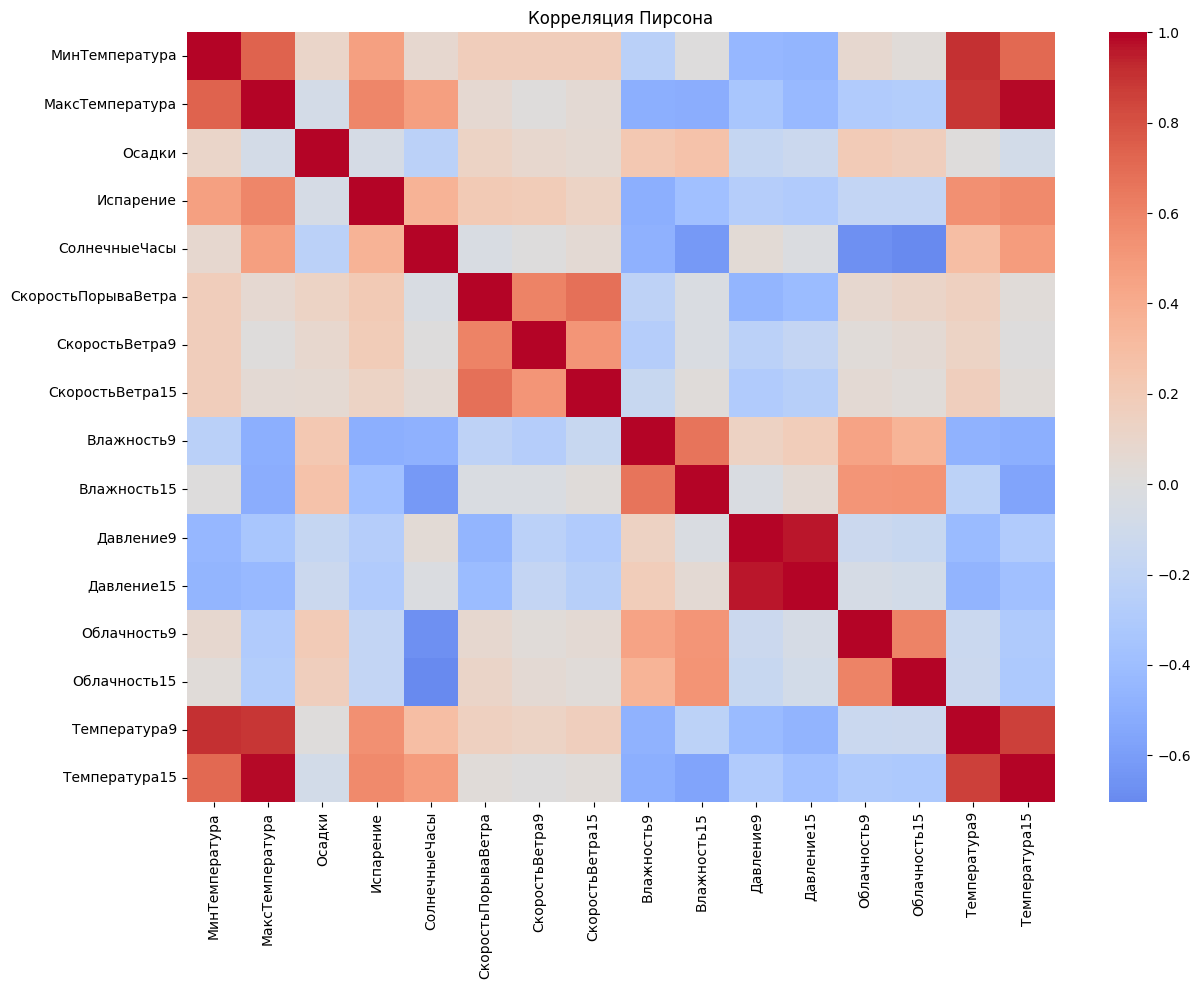

In [20]:
plt.figure(figsize=(14, 10))
sns.heatmap(pearson_corr, cmap='coolwarm', center=0)
plt.title('Корреляция Пирсона')
plt.show()

### Корреляция Спирмена

Коэффициент Спирмена рассчитывается по рангам, показывает силу **монотонной** связи и меньше зависит от выбросов.

In [21]:
spearman_corr = num_data.corr(method='spearman')
spearman_corr

,МинТемпература,МаксТемпература,Осадки,Испарение,СолнечныеЧасы,СкоростьПорываВетра,СкоростьВетра9,СкоростьВетра15,Влажность9,Влажность15,Давление9,Давление15,Облачность9,Облачность15,Температура9,Температура15
МинТемпература,1.000000,0.737995,0.022430,0.580826,0.112804,0.202158,0.178792,0.181599,-0.220004,0.029939,-0.464640,-0.469161,0.066801,0.011773,0.898786,0.709459
МаксТемпература,0.737995,1.000000,-0.298381,0.696536,0.498969,0.092262,0.023157,0.065133,-0.466274,-0.460341,-0.354260,-0.444848,-0.292528,-0.287673,0.891658,0.984476
Осадки,0.022430,-0.298381,1.000000,-0.309316,-0.401306,0.125966,0.082724,0.068072,0.444416,0.443635,-0.154643,-0.063457,0.374025,0.321911,-0.154997,-0.305057
Испарение,0.580826,0.696536,-0.309316,1.000000,0.447677,0.258016,0.208744,0.180828,-0.559997,-0.408272,-0.344737,-0.372165,-0.209399,-0.217575,0.671929,0.677092
СолнечныеЧасы,0.112804,0.498969,-0.401306,0.447677,1.000000,-0.006614,0.026060,0.057096,-0.529891,-0.620349,0.015381,-0.051296,-0.688205,-0.719146,0.331427,0.520601
СкоростьПорываВетра,0.202158,0.092262,0.125966,0.258016,-0.006614,1.000000,0.588882,0.680641,-0.232123,-0.046528,-0.428987,-0.383095,0.058658,0.094991,0.174999,0.057451
СкоростьВетра9,0.178792,0.023157,0.082724,0.208744,0.026060,0.588882,1.000000,0.486212,-0.287393,-0.036024,-0.212712,-0.162757,0.016801,0.046771,0.135658,0.012286
СкоростьВетра15,0.181599,0.065133,0.068072,0.180828,0.057096,0.680641,0.486212,1.000000,-0.157809,0.025167,-0.281428,-0.238538,0.046943,0.016832,0.172298,0.044418
Влажность9,-0.220004,-0.466274,0.444416,-0.559997,-0.529891,-0.232123,-0.287393,-0.157809,1.000000,0.637240,0.126877,0.174168,0.481854,0.375549,-0.443002,-0.460092
Влажность15,0.029939,-0.460341,0.443635,-0.408272,-0.620349,-0.046528,-0.036024,0.025167,0.637240,1.000000,-0.022240,0.057975,0.530118,0.539534,-0.182360,-0.509107


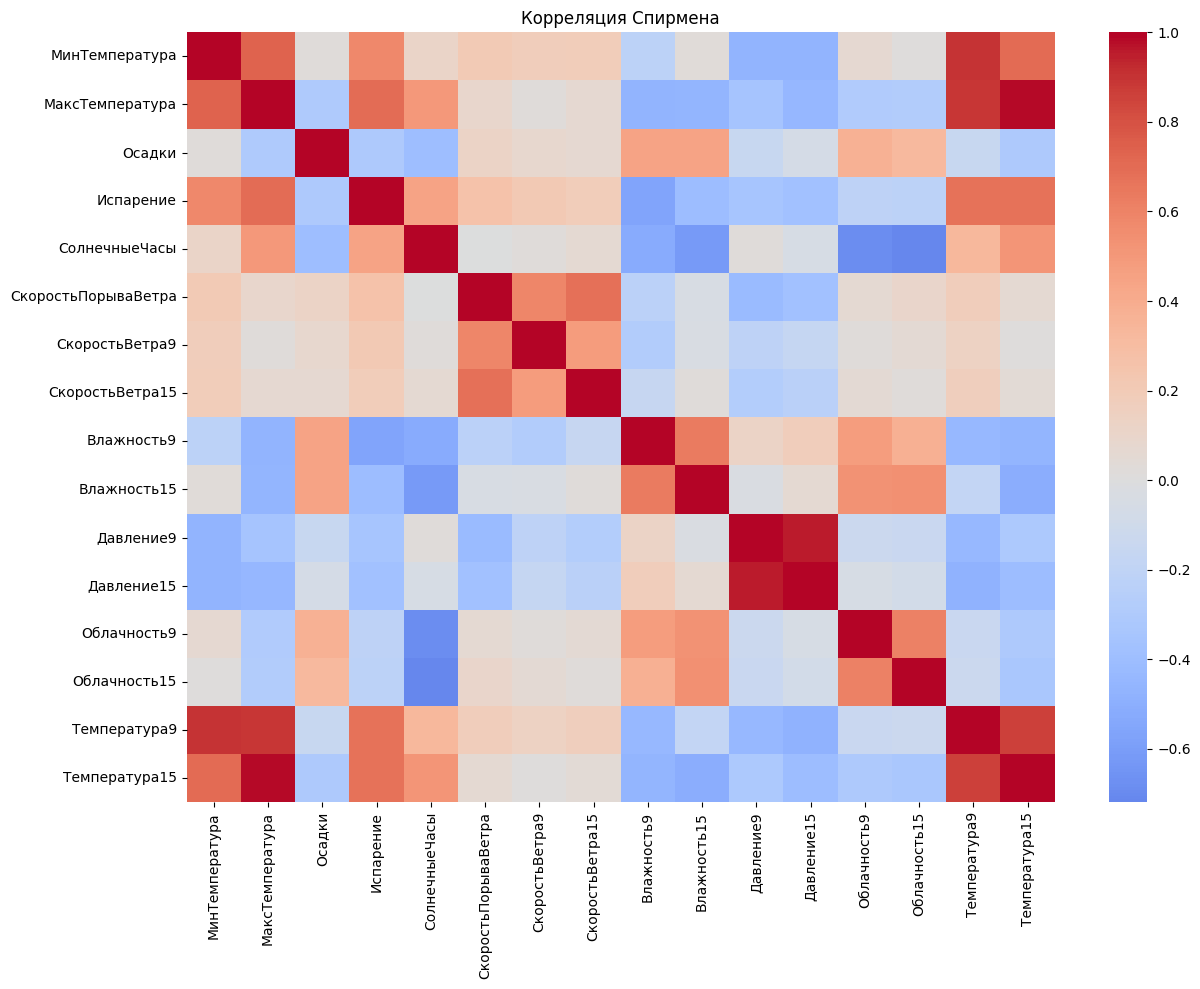

In [22]:
plt.figure(figsize=(14, 10))
sns.heatmap(spearman_corr, cmap='coolwarm', center=0)
plt.title('Корреляция Спирмена')
plt.show()

### Сильные корреляции

Выведем пары, у которых модуль коэффициента корреляции не меньше 0,7. Единицы на главной диагонали и повторяющиеся пары исключены.

In [ ]:
mask = np.triu(np.ones(pearson_corr.shape), k=1).astype(bool)

pearson_pairs = pearson_corr.where(mask).stack().sort_values(key=abs, ascending=False)
spearman_pairs = spearman_corr.where(mask).stack().sort_values(key=abs, ascending=False)

print('Сильные корреляции Пирсона:')
print(pearson_pairs[abs(pearson_pairs) >= 0.7])
print('Сильные корреляции Спирмена:')
print(spearman_pairs[abs(spearman_pairs) >= 0.7])

Сильные корреляции Пирсона:
МаксТемпература  Температура15      0.984503
Давление9        Давление15         0.961326
МинТемпература   Температура9       0.901821
МаксТемпература  Температура9       0.887210
Температура9     Температура15      0.860591
МинТемпература   МаксТемпература    0.736555
                 Температура15      0.708906
СолнечныеЧасы    Облачность15      -0.703930
dtype: float64
Сильные корреляции Спирмена:
МаксТемпература  Температура15      0.984476
Давление9        Давление15         0.959588
МинТемпература   Температура9       0.898786
МаксТемпература  Температура9       0.891658
Температура9     Температура15      0.864564
МинТемпература   МаксТемпература    0.737995
СолнечныеЧасы    Облачность15      -0.719146
МинТемпература   Температура15      0.709459
dtype: float64


### Аналитика среднего уровня

Центральные 50% максимальной температуры находятся между **17,9°C и 28,2°C**, а минимальной - между **7,6°C и 16,9°C**. У осадков Q1 и медиана равны 0 мм, Q3 равен 0,8 мм. Это подтверждает большое количество сухих дней и правую асимметрию распределения.

Оба метода показали очень сильные положительные связи между `МаксТемпература` и `Температура15`, между `Давление9` и `Давление15`, а также между `МинТемпература` и `Температура9`. По Спирмену также обнаружена сильная отрицательная связь между `СолнечныеЧасы` и `Облачность15`: при большей облачности солнечных часов обычно меньше.

Результаты Пирсона и Спирмена близки для температуры и давления. Для признаков с выбросами и асимметрией надежнее дополнительно учитывать Спирмена. Корреляция показывает связь, но не доказывает причинность.

## 2.3. Повышенный уровень

### Типичный диапазон и выбросы

Используем правило IQR. Типичный диапазон находится между `Q1 - 1.5 * IQR` и `Q3 + 1.5 * IQR`.

In [24]:
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = num_data.lt(lower) | num_data.gt(upper)

outlier_info = pd.DataFrame({
    'lower_bound': lower,
    'upper_bound': upper,
    'outlier_count': outliers.sum(),
    'outlier_percent': outliers.sum() / num_data.count() * 100,
    'min': num_data.min(),
    'max': num_data.max()
}).sort_values('outlier_count', ascending=False)

outlier_info

,lower_bound,upper_bound,outlier_count,outlier_percent,min,max
Осадки,-1.20,2.00,25578,17.987468,0.0,371.0
СкоростьПорываВетра,5.50,73.50,3092,2.287033,6.0,135.0
СкоростьВетра15,-3.50,40.50,2523,1.771795,0.0,87.0
Испарение,-4.60,14.60,1995,2.413209,0.0,145.0
СкоростьВетра9,-11.00,37.00,1817,1.264501,0.0,130.0
Влажность9,18.00,122.00,1425,0.997857,0.0,100.0
Давление9,998.65,1036.65,1191,0.913379,980.5,1041.0
Давление15,996.00,1034.40,919,0.704582,977.1,1039.6
Температура15,1.90,41.10,764,0.538593,-5.4,46.7
МаксТемпература,2.45,43.65,489,0.339115,-4.8,48.1


### Строки за пределами типичного диапазона

In [28]:
outlier_rows = data[outliers.any(axis=1)]
print('Количество строк хотя бы с одним выбросом:', len(outlier_rows))
outlier_rows.head()

Количество строк хотя бы с одним выбросом: 33285


,Дата,Место,МинТемпература,МаксТемпература,Осадки,Испарение,СолнечныеЧасы,НаправлениеПорываВетра,СкоростьПорываВетра,НаправлениеВетра9,...,Влажность9,Влажность15,Давление9,Давление15,Облачность9,Облачность15,Температура9,Температура15,ДождьСегодня,ДождьЗавтра
8,2008-12-09,Albury,9.7,31.9,0.0,NaN,NaN,NNW,80.0,SE,...,42.0,9.0,1008.9,1003.6,NaN,NaN,18.3,30.2,No,Yes
11,2008-12-12,Albury,15.9,21.7,2.2,NaN,NaN,NNE,31.0,NE,...,89.0,91.0,1010.5,1004.2,8.0,8.0,15.9,17.0,Yes,Yes
12,2008-12-13,Albury,15.9,18.6,15.6,NaN,NaN,W,61.0,NNW,...,76.0,93.0,994.3,993.0,8.0,8.0,17.4,15.8,Yes,Yes
13,2008-12-14,Albury,12.6,21.0,3.6,NaN,NaN,SW,44.0,W,...,65.0,43.0,1001.2,1001.8,NaN,7.0,15.8,19.8,Yes,No
17,2008-12-18,Albury,13.5,22.9,16.8,NaN,NaN,W,63.0,N,...,80.0,65.0,1005.8,1002.2,8.0,1.0,18.0,21.5,Yes,Yes


### Корреляция данных после выброса

In [ ]:
clean_data = data.loc[~outliers.any(axis=1)].copy()
clean_num_data = clean_data[numeric_cols]
pearson_clean = clean_num_data.corr(method='pearson')
pearson_clean

,МинТемпература,МаксТемпература,Осадки,Испарение,СолнечныеЧасы,СкоростьПорываВетра,СкоростьВетра9,СкоростьВетра15,Влажность9,Влажность15,Давление9,Давление15,Облачность9,Облачность15,Температура9,Температура15
МинТемпература,1.000000,0.737839,-0.001852,0.580090,0.106652,0.234684,0.217071,0.221930,-0.266127,0.023906,-0.513867,-0.505958,0.074373,0.009923,0.905855,0.709441
МаксТемпература,0.737839,1.000000,-0.197898,0.687575,0.476626,0.169237,0.069770,0.106388,-0.477125,-0.479053,-0.446657,-0.516696,-0.262409,-0.257598,0.875848,0.984459
Осадки,-0.001852,-0.197898,1.000000,-0.206659,-0.239973,0.049214,0.036664,0.036362,0.247323,0.256835,-0.042771,0.014505,0.211126,0.190027,-0.104977,-0.201724
Испарение,0.580090,0.687575,-0.206659,1.000000,0.392209,0.288859,0.240545,0.198094,-0.555136,-0.381721,-0.406800,-0.414115,-0.163770,-0.185972,0.656844,0.667251
СолнечныеЧасы,0.106652,0.476626,-0.239973,0.392209,1.000000,0.038888,0.048476,0.100961,-0.427546,-0.571220,-0.036059,-0.092658,-0.645128,-0.684278,0.304605,0.497880
СкоростьПорываВетра,0.234684,0.169237,0.049214,0.288859,0.038888,1.000000,0.559730,0.663735,-0.305342,-0.103443,-0.409410,-0.377506,0.025343,0.064416,0.232581,0.135736
СкоростьВетра9,0.217071,0.069770,0.036664,0.240545,0.048476,0.559730,1.000000,0.456805,-0.330463,-0.074672,-0.183636,-0.142536,-0.001978,0.021803,0.179211,0.060715
СкоростьВетра15,0.221930,0.106388,0.036362,0.198094,0.100961,0.663735,0.456805,1.000000,-0.178175,0.014226,-0.269657,-0.235416,0.035615,-0.001764,0.226332,0.084604
Влажность9,-0.266127,-0.477125,0.247323,-0.555136,-0.427546,-0.305342,-0.330463,-0.178175,1.000000,0.609761,0.223934,0.253251,0.386103,0.305832,-0.475153,-0.471225
Влажность15,0.023906,-0.479053,0.256835,-0.381721,-0.571220,-0.103443,-0.074672,0.014226,0.609761,1.000000,0.027960,0.100703,0.468017,0.474243,-0.175572,-0.533209


In [ ]:
spearman_clean = clean_num_data.corr(method='spearman')
spearman_clean

,МинТемпература,МаксТемпература,Осадки,Испарение,СолнечныеЧасы,СкоростьПорываВетра,СкоростьВетра9,СкоростьВетра15,Влажность9,Влажность15,Давление9,Давление15,Облачность9,Облачность15,Температура9,Температура15
МинТемпература,1.000000,0.740474,-0.041787,0.619222,0.153010,0.242660,0.212994,0.220656,-0.258281,0.037555,-0.515831,-0.503321,0.068344,0.003674,0.901413,0.711187
МаксТемпература,0.740474,1.000000,-0.256325,0.711900,0.507958,0.175997,0.073798,0.113795,-0.451599,-0.442214,-0.455870,-0.521865,-0.264288,-0.264131,0.882453,0.984631
Осадки,-0.041787,-0.256325,1.000000,-0.270978,-0.288504,0.017631,0.015536,0.021173,0.311716,0.302533,-0.010248,0.048435,0.256518,0.224250,-0.161072,-0.260132
Испарение,0.619222,0.711900,-0.270978,1.000000,0.460151,0.307671,0.234593,0.217529,-0.555034,-0.362984,-0.427949,-0.434262,-0.167132,-0.193526,0.697075,0.691174
СолнечныеЧасы,0.153010,0.507958,-0.288504,0.460151,1.000000,0.061598,0.064373,0.094280,-0.472759,-0.554419,-0.069508,-0.124878,-0.642539,-0.685335,0.352530,0.528918
СкоростьПорываВетра,0.242660,0.175997,0.017631,0.307671,0.061598,1.000000,0.553792,0.667907,-0.306981,-0.116503,-0.393001,-0.359899,0.019863,0.054701,0.237168,0.143164
СкоростьВетра9,0.212994,0.073798,0.015536,0.234593,0.064373,0.553792,1.000000,0.442305,-0.339151,-0.076024,-0.180261,-0.139916,-0.004330,0.019171,0.177797,0.063728
СкоростьВетра15,0.220656,0.113795,0.021173,0.217529,0.094280,0.667907,0.442305,1.000000,-0.181025,0.027745,-0.266777,-0.230269,0.038189,-0.001681,0.224014,0.093002
Влажность9,-0.258281,-0.451599,0.311716,-0.555034,-0.472759,-0.306981,-0.339151,-0.181025,1.000000,0.589742,0.208295,0.238399,0.404233,0.319844,-0.454955,-0.445427
Влажность15,0.037555,-0.442214,0.302533,-0.362984,-0.554419,-0.116503,-0.076024,0.027745,0.589742,1.000000,0.034073,0.105401,0.481064,0.481488,-0.151080,-0.493995


In [ ]:
mask = np.triu(np.ones(pearson_clean.shape), k=1).astype(bool)

pearson_clean_pairs = pearson_clean.where(mask).stack().sort_values(key=abs, ascending=False)
spearman_clean_pairs = spearman_clean.where(mask).stack().sort_values(key=abs, ascending=False)

print('Сильные корреляции Пирсона:')
print(pearson_clean_pairs[abs(pearson_pairs) >= 0.7])
print('Сильные корреляции Спирмена:')
print(spearman_clean_pairs[abs(spearman_pairs) >= 0.7])

Сильные корреляции Пирсона:
МаксТемпература  Температура15      0.984459
Давление9        Давление15         0.964474
МинТемпература   Температура9       0.905855
МаксТемпература  Температура9       0.875848
Температура9     Температура15      0.847847
МинТемпература   МаксТемпература    0.737839
                 Температура15      0.709441
dtype: float64
Сильные корреляции Спирмена:
МаксТемпература  Температура15      0.984631
Давление9        Давление15         0.963156
МинТемпература   Температура9       0.901413
МаксТемпература  Температура9       0.882453
Температура9     Температура15      0.854326
МинТемпература   МаксТемпература    0.740474
МаксТемпература  Испарение          0.711900
МинТемпература   Температура15      0.711187
dtype: float64


In [ ]:
correlation_compare = pd.DataFrame({
    'pearson_before': pearson_pairs,
    'pearson_after': pearson_clean_pairs,
    'spearman_before': spearman_pairs,
    'spearman_after': spearman_clean_pairs
})

correlation_compare

pearson_before  pearson_after  \
Влажность15   Давление15                 0.100703       0.100703   
              Давление9                  0.027960       0.027960   
              Облачность15               0.474243       0.474243   
              Облачность9                0.468017       0.468017   
              Температура15             -0.533209      -0.533209   
...                                           ...            ...   
СолнечныеЧасы СкоростьВетра9             0.048476       0.048476   
              СкоростьПорываВетра        0.038888       0.038888   
              Температура15              0.497880       0.497880   
              Температура9               0.304605       0.304605   
Температура9  Температура15              0.847847       0.847847   

                                   spearman_before  spearman_after  
Влажность15   Давление15                  0.105401        0.105401  
              Давление9                   0.034073        0.034073  
              Облачность15                0.481488        0.481488  
              Облачность9                 0.481064        0.481064  
              Температура15              -0.493995       -0.493995  
...                                            ...             ...  
СолнечныеЧасы СкоростьВетра9              0.064373        0.064373  
              СкоростьПорываВетра         0.061598        0.061598  
              Температура15               0.528918        0.528918  
              Температура9                0.352530        0.352530  
Температура9  Температура15               0.854326        0.854326  

[120 rows x 4 columns]

### Анализ корреляции после удаления выбросов

После определения выбросов была создана отдельная таблица `clean_data`, из которой исключены строки, содержащие хотя бы один числовой выброс по правилу 1,5 IQR. Исходная таблица `data` не изменялась.

Для очищенных данных рассчитаны матрицы корреляции Пирсона и Спирмена. Пирсон показывает линейную связь, а Спирмен - монотонную связь и меньше зависит от экстремальных значений.

После удаления выбросов основные сильные связи сохранились между максимальной температурой и температурой в 15:00, между давлением в 9:00 и 15:00, а также между минимальной температурой и температурой в 9:00. Это показывает, что данные связи не объясняются только выбросами.

Если коэффициенты до и после очистки близки, связь является устойчивой. Если коэффициенты заметно изменились, значит, выбросы существенно влияли на результат. Различия между Пирсоном и Спирменом особенно важны для осадков и испарения, так как эти признаки имеют асимметричное распределение.

Удаление выбросов в данном анализе является статистическим способом проверки устойчивости результатов. Потенциальный выброс не обязательно является ошибкой: сильный дождь или порыв ветра могут быть реальными погодными явлениями.

## Вывод

### Общая струкрутра данных

В работе использован набор погодных данных Австралии. Таблица содержит 145 460 наблюдений и 23 признака. В данных представлены дата наблюдения, место, минимальная и максимальная температура, осадки, испарение, солнечное сияние, направление и скорость ветра, влажность, давление, облачность, а также информация о наличии дождя сегодня и завтра.

Среди признаков есть числовые и категориальные данные. К числовым относятся температура, осадки, скорость ветра, влажность, давление, облачность и другие показатели. К категориальным относятся место наблюдения, направления ветра и признаки ДождьСегодня и ДождьЗавтра. В таблице присутствуют пропущенные значения, особенно в признаках солнечного сияния, испарения и облачности.

### Наиболее информативные характеристики
Для анализа центра распределения наиболее полезными оказались среднее и медиана. Среднее показывает общий уровень значений, а медиана меньше зависит от выбросов. Для оценки разброса использовались стандартное отклонение и дисперсия.

Для признаков с асимметричным распределением более информативными оказались квартили и межквартильный размах. Особенно это относится к осадкам: медиана равна 0 мм, потому что большинство дней были без дождя, но среднее значение больше из-за отдельных дней с сильными осадками.

Также были рассчитаны коэффициенты корреляции Пирсона и Спирмена. Пирсон показывает линейную связь между признаками, а Спирмен - монотонную связь и меньше зависит от выбросов. Оба метода показали сильные взаимосвязи между температурными признаками, между давлением в 9:00 и 15:00, а также отрицательную связь солнечного сияния и облачности.

### Распределение значений
Температурные признаки имеют сравнительно устойчивое распределение: средние значения и медианы находятся близко друг к другу. Центральные 50% значений максимальной температуры находятся примерно в диапазоне от 17,9°C до 28,2°C.

Распределение осадков отличается от распределения температур. Большинство значений осадков равны нулю или близки к нулю, поэтому медиана равна 0 мм. При этом встречаются дни с большими значениями осадков, из-за чего распределение имеет правый хвост, а среднее значение становится больше медианы.

Категориальные признаки ДождьСегодня и ДождьЗавтра распределены неравномерно: значение No встречается чаще значения Yes. Направления ветра распределены более равномерно.

### Наличие выбросов
Значения за пределами этого диапазона считались потенциальными выбросами. Хотя бы один потенциальный выброс был найден в 33285 строках. Больше всего выбросов обнаружено в признаке Осадки, поскольку основная часть значений равна нулю, а отдельные сильные дожди значительно превышают обычный уровень.

Найденные выбросы не обязательно являются ошибками. Сильный дождь, высокая скорость порыва ветра или большое испарение могут быть реальными погодными явлениями. Поэтому удалять все такие значения автоматически нельзя. Их нужно проверять по исходным данным и физическому смыслу.

### Качество данных
Данные подходят для описательного статистического анализа, однако требуют предварительной обработки перед дальнейшим использованием. Основными проблемами являются пропуски, выбросы и неравномерное распределение признаков дождя.

Полные дубликаты строк отсутствуют, но в отдельных признаках много пропущенных значений. Поэтому для каждого показателя необходимо отдельно выбрать способ обработки пропусков: удалить строки, заменить значения медианой или использовать другой подход.

В целом набор данных содержит полезную информацию о погоде и позволяет изучать распределение температур, осадков, влажности, давления и других показателей. Наиболее информативными характеристиками стали медиана, квартили, IQR, стандартное отклонение и корреляции Пирсона и Спирмена. Перед построением моделей необходимо обработать пропуски, проверить потенциальные выбросы и учитывать неравномерность категориальных признаков.